# EuroSAT — CNN vs MobileNetV3 Transfer Learning

Personal project | PyTorch | Satellite image classification

## 1. Dataset

EuroSAT contains 27,000 RGB satellite images in 10 land-use classes. We use 70% for training, 15% for validation and 15% for testing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, models
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


100%|██████████| 94.3M/94.3M [00:00<00:00, 96.8MB/s]


Images: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


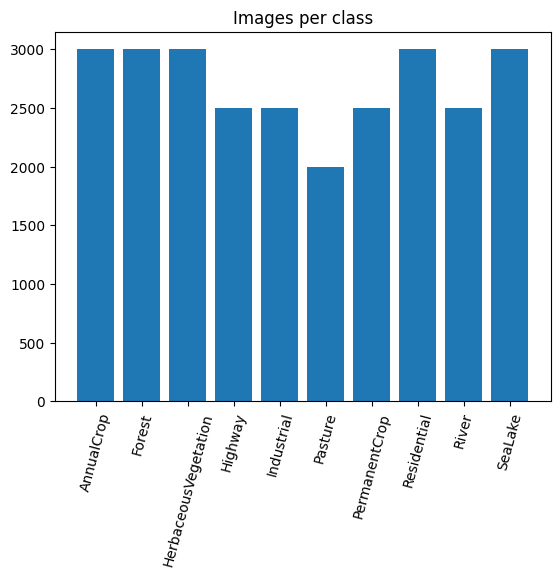

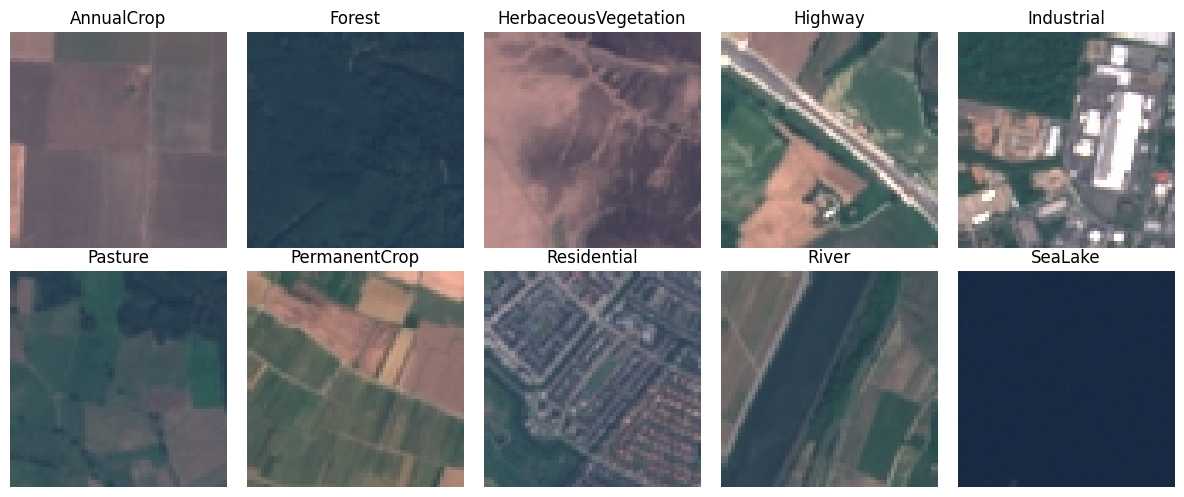

In [2]:
data = datasets.EuroSAT(root='data', download=True)
classes = data.classes
print('Images:', len(data))
print('Classes:', classes)

labels = [label for _, label in data.samples]
plt.bar(classes, np.bincount(labels))
plt.xticks(rotation=75)
plt.title('Images per class')
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    index = labels.index(i)
    image, label = data[index]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

### Prepare the images

Images are resized to 128 × 128 and converted to PyTorch tensors manually. ImageNet normalization is used for compatibility with the pretrained MobileNetV3 weights.

In [3]:
class EuroSATImages(Dataset):
    def __init__(self, subset):
        self.subset = subset

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, index):
        image, label = self.subset[index]
        image = image.resize((128, 128))
        image = np.array(image, dtype=np.float32) / 255.0
        image = torch.tensor(image).permute(2, 0, 1)
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        image = (image - mean) / std
        return image, label

train_size = int(0.70 * len(data))
val_size = int(0.15 * len(data))
test_size = len(data) - train_size - val_size
train_set, val_set, test_set = random_split(
    data, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(EuroSATImages(train_set), batch_size=64, shuffle=True)
val_loader = DataLoader(EuroSATImages(val_set), batch_size=64)
test_loader = DataLoader(EuroSATImages(test_set), batch_size=64)
print('Train:', train_size, 'Validation:', val_size, 'Test:', test_size)

Train: 18900 Validation: 4050 Test: 4050


## 2. Simple CNN

A small CNN with three convolutional layers, ReLU and MaxPooling, trained from scratch.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

### Training

The same simple training function is used for both models.

Epoch 1/5 - loss: 1.0209 - val accuracy: 0.732
Epoch 2/5 - loss: 0.6131 - val accuracy: 0.808
Epoch 3/5 - loss: 0.4812 - val accuracy: 0.854
Epoch 4/5 - loss: 0.3832 - val accuracy: 0.856
Epoch 5/5 - loss: 0.2876 - val accuracy: 0.856


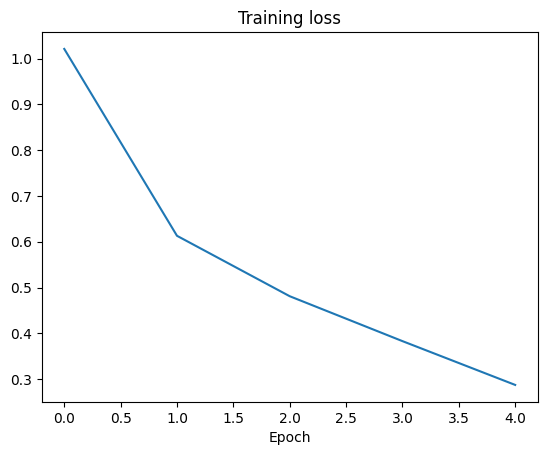

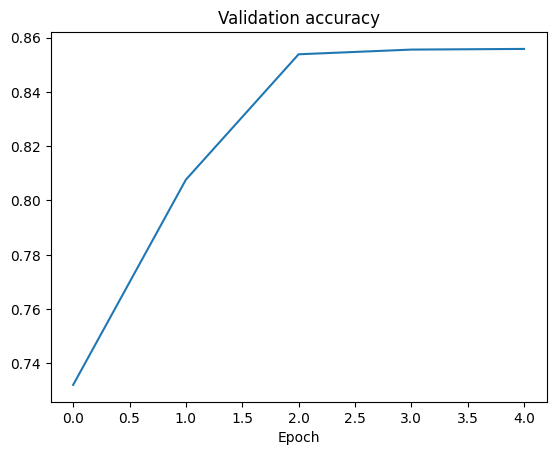

In [5]:
def train(model, epochs=5):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    train_losses, val_accuracies = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                outputs = model(images.to(device))
                predictions = outputs.argmax(dim=1).cpu()
                correct += (predictions == labels).sum().item()
                total += len(labels)

        train_losses.append(total_loss / len(train_loader))
        val_accuracies.append(correct / total)
        print(f'Epoch {epoch+1}/{epochs} - loss: {train_losses[-1]:.4f} - val accuracy: {val_accuracies[-1]:.3f}')

    plt.plot(train_losses)
    plt.title('Training loss')
    plt.xlabel('Epoch')
    plt.show()
    plt.plot(val_accuracies)
    plt.title('Validation accuracy')
    plt.xlabel('Epoch')
    plt.show()
    return model

cnn = CNN()
cnn = train(cnn)

## 3. Transfer Learning — MobileNetV3

We load MobileNetV3-Small pretrained on ImageNet, freeze its feature extractor, and train a new classifier for the 10 EuroSAT classes.

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 133MB/s]


Epoch 1/5 - loss: 0.5135 - val accuracy: 0.843
Epoch 2/5 - loss: 0.3330 - val accuracy: 0.899
Epoch 3/5 - loss: 0.2796 - val accuracy: 0.896
Epoch 4/5 - loss: 0.2340 - val accuracy: 0.909
Epoch 5/5 - loss: 0.2023 - val accuracy: 0.916


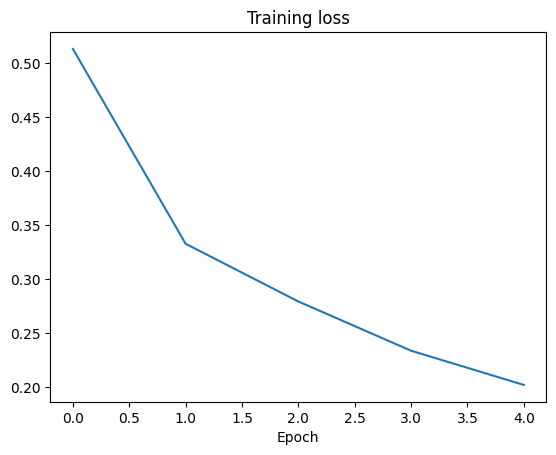

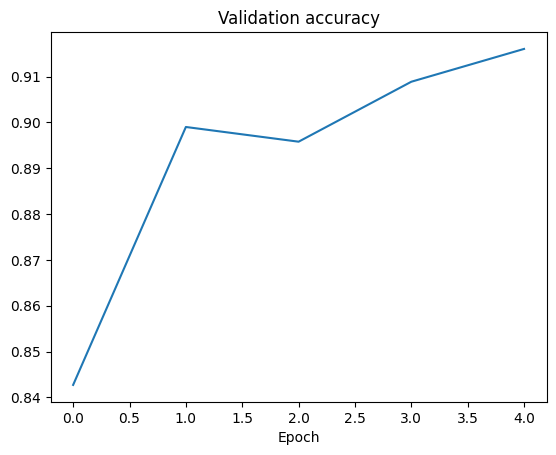

In [6]:
mobilenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

for parameter in mobilenet.features.parameters():
    parameter.requires_grad = False

mobilenet.classifier[-1] = nn.Linear(mobilenet.classifier[-1].in_features, 10)
mobilenet = train(mobilenet)

## 4. Test results — CNN vs MobileNetV3

CNN accuracy: 86.27%
MobileNetV3 accuracy: 90.69%


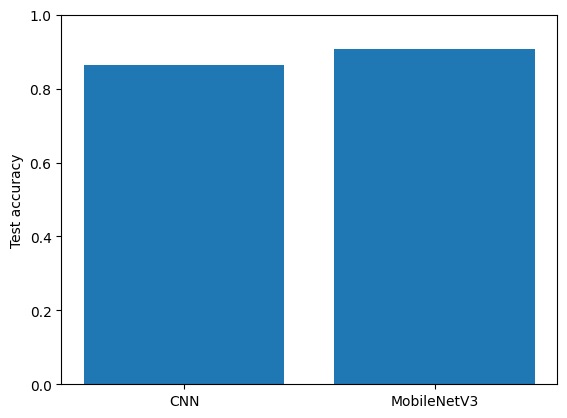

CNN classification report:
                      precision    recall  f1-score   support

          AnnualCrop       0.94      0.86      0.89       472
              Forest       0.92      0.95      0.94       442
HerbaceousVegetation       0.91      0.72      0.80       458
             Highway       0.82      0.69      0.75       391
          Industrial       0.94      0.93      0.94       378
             Pasture       0.84      0.84      0.84       299
       PermanentCrop       0.77      0.80      0.78       379
         Residential       0.89      0.98      0.93       450
               River       0.70      0.87      0.78       375
             SeaLake       0.90      0.98      0.94       406

            accuracy                           0.86      4050
           macro avg       0.86      0.86      0.86      4050
        weighted avg       0.87      0.86      0.86      4050

MobileNetV3 classification report:
                      precision    recall  f1-score   support

    

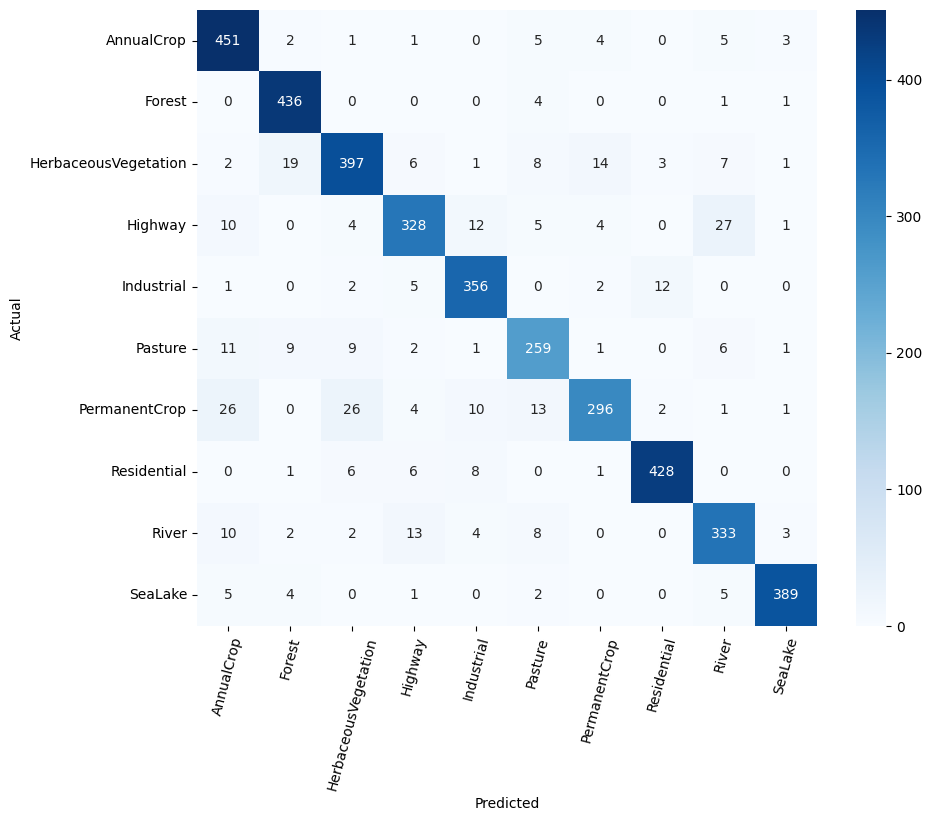

In [7]:
def test(model):
    model.eval()
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.numpy())
    accuracy = np.mean(np.array(true_labels) == np.array(predictions))
    return accuracy, true_labels, predictions

cnn_acc, cnn_true, cnn_pred = test(cnn)
mobile_acc, mobile_true, mobile_pred = test(mobilenet)

print(f'CNN accuracy: {cnn_acc:.2%}')
print(f'MobileNetV3 accuracy: {mobile_acc:.2%}')

plt.bar(['CNN', 'MobileNetV3'], [cnn_acc, mobile_acc])
plt.ylim(0, 1)
plt.ylabel('Test accuracy')
plt.show()

print('CNN classification report:')
print(classification_report(cnn_true, cnn_pred, target_names=classes))
print('MobileNetV3 classification report:')
print(classification_report(mobile_true, mobile_pred, target_names=classes))

cm = confusion_matrix(mobile_true, mobile_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=75)
plt.show()